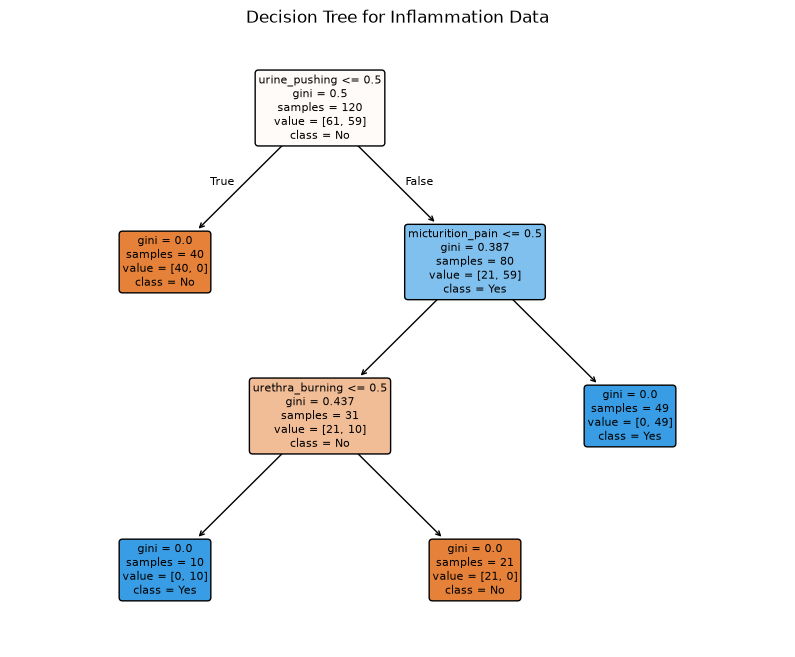

In [66]:
#1b Build a decision tree on the whole data set and plot it 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

columns = [
    "temperature", "nausea", "lumbar_pain", 
    "urine_pushing", "micturition_pain", "urethra_burning", 
    "bladder_inflammation", "nephritis"
]

df = pd.read_csv('acute+inflammations/diagnosis.data', 
                 sep='\t', 
                 header=None, 
                 names=columns, 
                 encoding='utf-16', 
                 decimal=',')
df.head()

# converting categorical to numeric
for col in df.columns[1:]:
    df[col] = df[col].map({'yes': 1, 'no': 0}).astype(int)
X = df.iloc[:, :6]
y = df['bladder_inflammation']

#tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X,y)

plt.figure(figsize=(10,8))
plot_tree(
    dt, feature_names=X.columns, 
    class_names = ['No', 'Yes'],
    filled=True, 
    rounded=True, 
    fontsize=8
)

plt.title('Decision Tree for Inflammation Data')
plt.show()

In [67]:
#1c Convert the decision rules into a set of IF-THEN rules
from sklearn.tree import export_text

rules = export_text(dt, feature_names=list(X.columns))
print(rules)

|--- urine_pushing <= 0.50
|   |--- class: 0
|--- urine_pushing >  0.50
|   |--- micturition_pain <= 0.50
|   |   |--- urethra_burning <= 0.50
|   |   |   |--- class: 1
|   |   |--- urethra_burning >  0.50
|   |   |   |--- class: 0
|   |--- micturition_pain >  0.50
|   |   |--- class: 1



CCP Alphas: [0.         0.11290323 0.14522177 0.24173611] 

      alpha  accuracy  leaves  depth
0  0.000000  1.000000       4      3
1  0.112903  0.783333       3      2
2  0.145222  0.808333       2      1
3  0.241736  0.708333       1      0 

Best alpha:  0.0
# of leaves:  4
Tree depth:  3


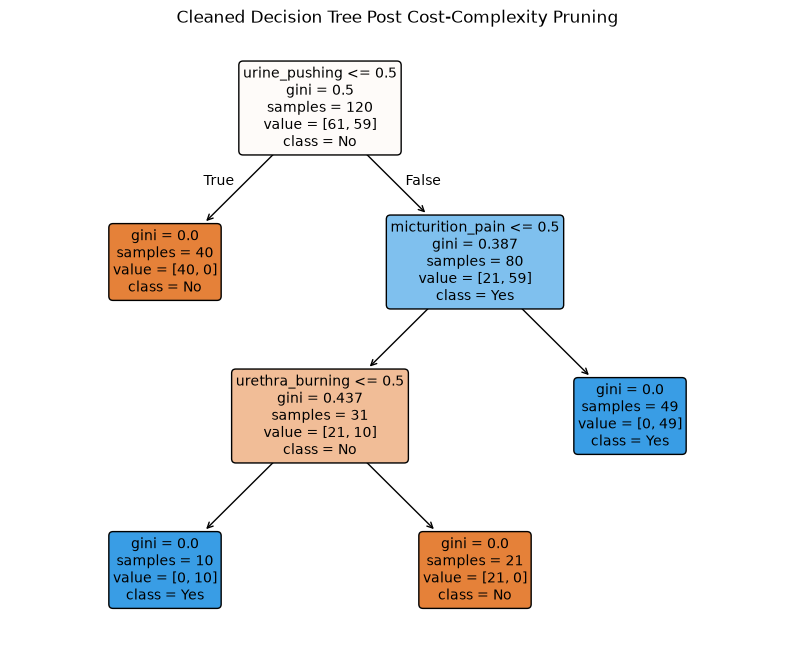

|--- urine_pushing <= 0.50
|   |--- class: 0
|--- urine_pushing >  0.50
|   |--- micturition_pain <= 0.50
|   |   |--- urethra_burning <= 0.50
|   |   |   |--- class: 1
|   |   |--- urethra_burning >  0.50
|   |   |   |--- class: 0
|   |--- micturition_pain >  0.50
|   |   |--- class: 1

Initial leaves:  4
Pruned leaves:  4
Initial depth:  3
Pruned depth:  3


In [68]:
#1d Use cost-complexity pruning to find a minimal decision tree and a set of decision 
# rules with high interpretability
path = dt.cost_complexity_pruning_path(X,y)
ccp_alphas = path.ccp_alphas
print("CCP Alphas:", ccp_alphas, "\n")


from sklearn.model_selection import cross_val_score
results =[]

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, 
    ccp_alpha=alpha)

    scores = cross_val_score(tree, X, y, cv=5)
    tree.fit(X,y)
    results.append({
        'alpha':alpha,
        'accuracy': scores.mean(), 
        'leaves': tree.get_n_leaves(),
        'depth': tree.get_depth()
    })
results_df = pd.DataFrame(results)
print(results_df, "\n")


#best one selection
best = results_df.sort_values(
    by=["accuracy", 'leaves', 'depth'],
    ascending=[False, True, True]
).iloc[0]

best_alpha = best['alpha']

cleaned_dt = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)
cleaned_dt.fit(X,y)
print("Best alpha: ", best_alpha)
print("# of leaves: ", cleaned_dt.get_n_leaves())
print("Tree depth: ", cleaned_dt.get_depth())


#plotting 
plt.figure(figsize=(10,8))

plot_tree(
    cleaned_dt,
    feature_names = X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Cleaned Decision Tree Post Cost-Complexity Pruning")
plt.show()

# identifying if-then rules
pruned_rules=export_text(
    cleaned_dt, 
    feature_names=list(X.columns)
)
print(pruned_rules) # new rules 

print("Initial leaves: ", dt.get_n_leaves())
print("Pruned leaves: ", cleaned_dt.get_n_leaves())

print('Initial depth: ', dt.get_depth())
print("Pruned depth: ", cleaned_dt.get_depth())

#1d interpretation
The leaves did not change in number, remaining 4 to 4. The selected tree kept the original structure, leaving the interpretation that there was no more pruning needed to improve the chosen balance between accuracy and interpretability. 

In [69]:
#2b Use a data imputation technique to deal with
# the missing values in the data set. The data description mentions some features
# are nonpredictive. Ignore those features.
import pandas as pd
from sklearn.impute import SimpleImputer

df = pd.read_csv('communities.data', header=None, na_values='?')

print(df.shape)
print(df.isna().sum().sum())

#remove nonpredictive features
df = df.drop(columns=[0,1,2,3,4])
print(df.shape)

#missing values
y = df.iloc[:, -1]

X = X.dropna(axis=1, how='all')
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values before: ", X.isna().sum().sum())
print("Missing values after: ", X_imputed.isna().sum().sum())
print("Final shape: ", X_imputed.shape)

(1994, 128)
39202
(1994, 123)
Missing values before:  0
Missing values after:  0
Final shape:  (120, 6)


                  temperature    nausea  lumbar_pain  urine_pushing  \
temperature          1.000000  0.593152     0.391971      -0.018866   
nausea               0.593152  1.000000     0.477105      -0.013765   
lumbar_pain          0.391971  0.477105     1.000000      -0.239046   
urine_pushing       -0.018866 -0.013765    -0.239046       1.000000   
micturition_pain     0.060493  0.574007    -0.183142       0.341816   
urethra_burning      0.037245 -0.121744     0.028571       0.597614   

                  micturition_pain  urethra_burning  
temperature               0.060493         0.037245  
nausea                    0.574007        -0.121744  
lumbar_pain              -0.183142         0.028571  
urine_pushing             0.341816         0.597614  
micturition_pain          1.000000         0.149331  
urethra_burning           0.149331         1.000000  


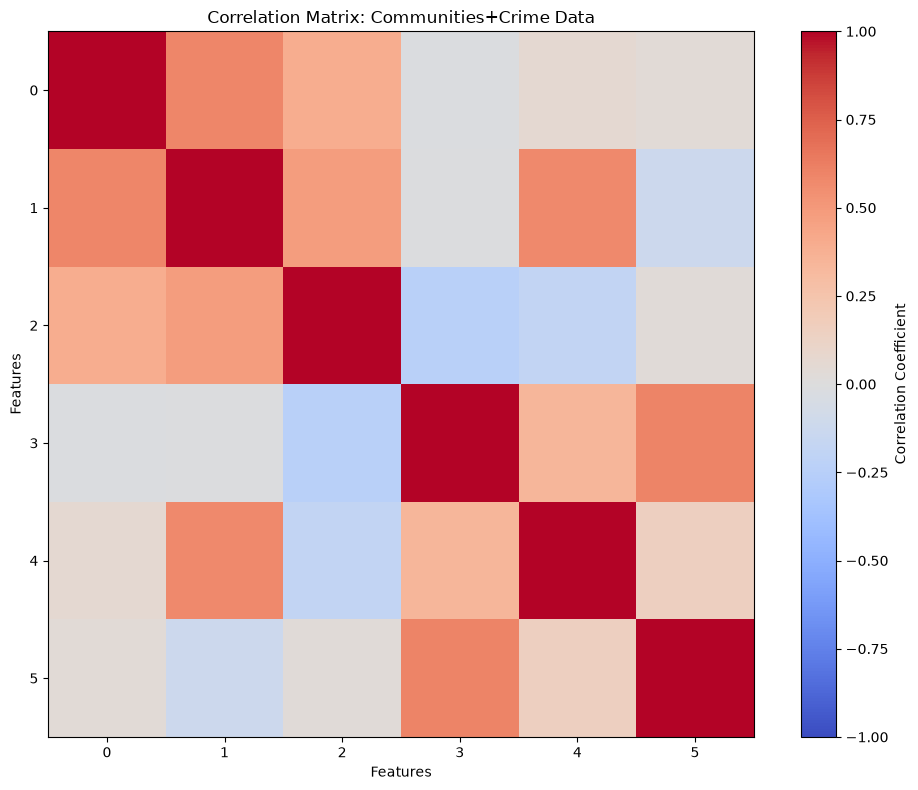

urine_pushing     urethra_burning     0.597614
temperature       nausea              0.593152
nausea            micturition_pain    0.574007
                  lumbar_pain         0.477105
temperature       lumbar_pain         0.391971
urine_pushing     micturition_pain    0.341816
lumbar_pain       urine_pushing       0.239046
                  micturition_pain    0.183142
micturition_pain  urethra_burning     0.149331
nausea            urethra_burning     0.121744
dtype: float64


In [79]:
#2c plot a correlation matrix for the features in the data set

corr_matrix = X_imputed.corr()
print(corr_matrix)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
plt.imshow(
    corr_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)
plt.colorbar(label='Correlation Coefficient')
plt.title("Correlation Matrix: Communities+Crime Data")
plt.xlabel('Features')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# strongest corr
import numpy as np
cleaning = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
correlations = corr_matrix.where(cleaning).stack()
print(correlations.abs().sort_values(ascending=False).head(10))


In [93]:
#2d calculate the Coefficient of Variation CV for each feature, where 
# where CV = s / m, in which s is sample standard deviation and m is sample mean

std = X_imputed.std(ddof=1)
mean=X_imputed.mean()

cv = std/mean

cv_df = pd.DataFrame({
    "Mean": mean,
    "Standard Deviation": std,
    "CV": cv
})
sorted_cv = cv_df.sort_values(by="CV", ascending=False)
print(sorted_cv)


                       Mean  Standard Deviation        CV
nausea             0.241667            0.429888  1.778848
urethra_burning    0.416667            0.495074  1.188177
micturition_pain   0.491667            0.502027  1.021071
lumbar_pain        0.583333            0.495074  0.848698
urine_pushing      0.666667            0.473381  0.710072
temperature       38.724167            1.819132  0.046977


In [72]:
#2e pick square root 128 features with highest CV, and make scatter plots and box plots
# for them

#2e Can you draw conclusions about significance of those features, just by the scatter plots? 

In [73]:
#2f Fit a linear model using least squares to the training set and report the test error

In [74]:
#2g Fit a ridge regression model on the training set, with chosen by cross-validation. 
# report the test error obtained.

In [75]:
#2h Fit a LASSO model on the training set, with chosen by cross-validation. Report test
# error obtained, along with a list of the variables selected by the model. Repeat with standardized features
# Report the test error for both cases and compare them. 

In [76]:
#2i Fit a PCR model on the training set, with M (the number of principal components) chosen
# by cross-validation. Report the test error obtained. 

In [77]:
#2j In this section, we would like to fit a boosting tree to the data. In the classification
# trees, one can use any type of regression at each node to build a multivariate regression tree. 
# Because the number of variables is large in this problem, one can use L1 penalized 
# regression at each node. etc. 